In [ ]:
#Meshal Mahnoor

GitHub link is available in GCR comment

Install dependencies:

In [1]:
# Install TorchCAM: the library that provides Grad-CAM++, Score-CAM
# and the Insertion / Deletion evaluation metrics
# -q = quiet output, -U = upgrade to the latest version
!pip install -q -U torchcam

In [2]:
import os # file / folder path handling
import torch # PyTorch core
import numpy as np # numerical arrays
import matplotlib.pyplot as plt # plotting images and heatmaps
# preprocessing + dataset loader
from torchvision import transforms, datasets
# DenseNet121 model + its ImageNet weights
from torchvision.models import densenet121, DenseNet121_Weights
# batches data for the model
from torch.utils.data import DataLoader
# reads image files
from PIL import Image
from functools import partial

from torchvision import transforms
from PIL import Image
# The two XAI (explanation) methods used in this lab
from torchcam.methods import GradCAMpp, ScoreCAM
# Metric that measures how faithful an explanation is
from torchcam.metrics import DeletionInsertionMetric

See if CUDA is available:

In [3]:
# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
# Use the GPU if one is available (much faster), otherwise fall back to the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


Load DenseNet:

In [4]:
# ------------------------------------------------------------
# Load pretrained DenseNet121
# ------------------------------------------------------------
# Weights trained on ImageNet-1K (1000 everyday object classes)
weights = DenseNet121_Weights.IMAGENET1K_V1
# Build the network, load the weights and move it to the GPU/CPU
model = densenet121(weights=weights).to(device)
# eval() switches off dropout / batch-norm updates -> deterministic predictions
model.eval()
print("DenseNet121 classifier loaded")
# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------
print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: DenseNet121")
print("Architecture: Convolutional Neural Network")
# DenseNet121 always has 4 dense blocks, so the value is hard-coded here
print("Number of Dense Blocks:", len(model.features.denseblock.__dict__) if False else
4)
# The final linear layer has one output per ImageNet class
print("Number of output classes:", model.classifier.out_features)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 102MB/s]


DenseNet121 classifier loaded

MODEL CONFIGURATION
--------------------------------------------------
Model: DenseNet121
Architecture: Convolutional Neural Network
Number of Dense Blocks: 4
Number of output classes: 1000


Load the same dataset as last lab:

In [6]:
# Folder containing one sub-folder per class (folder name = ImageNet class ID)
DATA_ROOT = "/content/drive/MyDrive/CV Lab + Class/data2"
# Same preprocessing that DenseNet121 was trained with
transform = transforms.Compose([
transforms.Resize((256, 256)), # resize image to 256x256
transforms.CenterCrop(224), # crop the central 224x224 region
transforms.ToTensor(), # convert to a tensor with values in [0, 1]
transforms.Normalize( # standardise with ImageNet mean / std
mean=[0.485, 0.456, 0.406],
std=[0.229, 0.224, 0.225]
)
])
# ImageFolder reads images and uses each sub-folder name as the class label
dataset = datasets.ImageFolder(
root=DATA_ROOT,
transform=transform
)
print(f"\nDataset size: {len(dataset)}")
print(f"Number of folders: {len(dataset.classes)}")
print(f"Folders: {dataset.classes}")


Dataset size: 41
Number of folders: 34
Folders: ['00001', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019', '00020', '00071', '00146', '00150', '00151', '00152', '00153', '00154', '00155', '00156', '00157', '00158', '00159', '00160', '00185', '00186', '00284', '00438', '00444', '00463', '00491', '00492', '00494', '00587', '00719']


Make the class names human readable:

In [7]:
# batch_size=1 -> one image at a time (needed for per-image explanations)
# shuffle=False -> keep the original order so dataset indices stay valid
dataloader = DataLoader(
dataset,
batch_size=1,
shuffle=False,
num_workers=0
)
# List of the 1000 human-readable class names (index -> name)
id2label = weights.meta["categories"]
print("\nNumber of ImageNet labels:", len(id2label))


Number of ImageNet labels: 1000


Predictions:

In [17]:
# Inference on the complete dataset
results = [] # will hold one dictionary per image
model.eval()
# no_grad() -> we only predict here, so gradients are not needed (saves memory)
with torch.no_grad():
  for idx, (images, labels) in enumerate(dataloader):
    images = images.to(device)
# Original image information
    img_path, true_label_idx = dataset.samples[idx]
    folder_name = os.path.basename(os.path.dirname(img_path))
    file_name = os.path.basename(img_path)
# Forward pass: image -> 1000 raw scores (logits)
    logits = model(images)
# Softmax turns the logits into probabilities
    probs = torch.softmax(logits, dim=-1)
# Top-1 prediction = class with the highest probability
    pred_class_idx = torch.argmax(probs, dim=-1).item()
    confidence = probs[0, pred_class_idx].item()
    pred_label = id2label[pred_class_idx]
# Top-5 predictions = five most likely classes
    top5_probs, top5_indices = torch.topk(
      probs,
      k=5,
      dim=-1
    )
    top5_predictions = []
    for rank in range(5):
      class_idx = top5_indices[0, rank].item()
      class_prob = top5_probs[0, rank].item()
      class_label = id2label[class_idx]
      top5_predictions.append({
        "rank": rank + 1,
        "class_index": class_idx,
        "label": class_label,
        "confidence": class_prob
      })
# Store all results for later use
    results.append({
      "dataset_index": idx,
      "image_path": img_path,
      "file_name": file_name,
      "folder_name": folder_name,
      "true_label_idx": true_label_idx,
      "pred_class_idx": pred_class_idx,
      "pred_label": pred_label,
      "confidence": confidence,
      "top5": top5_predictions
    })
# Progress message every 10 images and at the very end
    if (idx + 1) % 10 == 0 or (idx + 1) == len(dataset):
      print(f"Processed {idx + 1}/{len(dataset)} images")

print("\nInference completed.")
print(f"Total images processed: {len(results)}")

Processed 10/41 images
Processed 20/41 images
Processed 30/41 images
Processed 40/41 images
Processed 41/41 images

Inference completed.
Total images processed: 41


prediction inspection on selected images:


DATASET INDEX: 0
Image file: 4688179944691877.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00001/4688179944691877.jpg
Folder name (GT): 00001
Dataset label index: 0

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 1
Predicted label: goldfish
Confidence: 0.5454

TOP-5 PREDICTIONS
--------------------------------------------------
1. goldfish (Class index: 1, Confidence: 0.5454)
2. eft (Class index: 27, Confidence: 0.0933)
3. stinkhorn (Class index: 994, Confidence: 0.0712)
4. American lobster (Class index: 122, Confidence: 0.0512)
5. starfish (Class index: 327, Confidence: 0.0340)


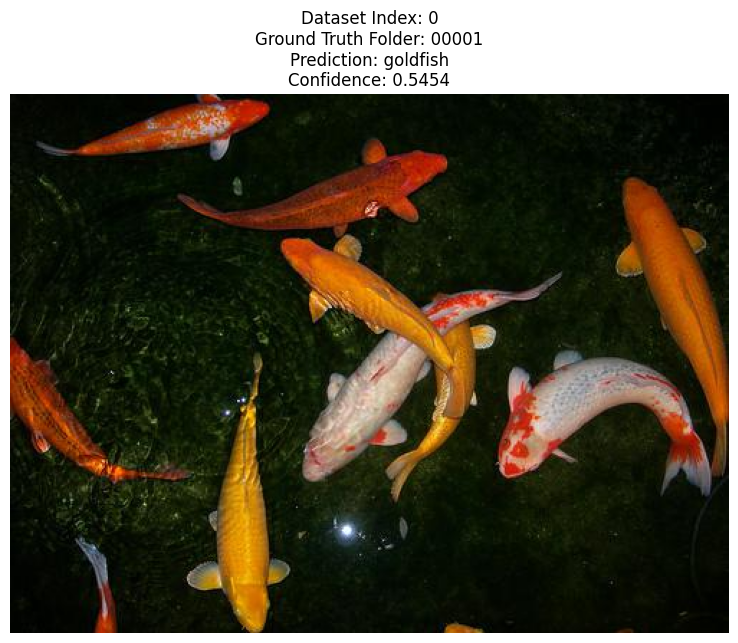


DATASET INDEX: 1
Image file: 352807011784034.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00012/352807011784034.jpg
Folder name (GT): 00012
Dataset label index: 1

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 12
Predicted label: house finch
Confidence: 0.9870

TOP-5 PREDICTIONS
--------------------------------------------------
1. house finch (Class index: 12, Confidence: 0.9870)
2. brambling (Class index: 10, Confidence: 0.0043)
3. partridge (Class index: 86, Confidence: 0.0043)
4. indigo bunting (Class index: 14, Confidence: 0.0007)
5. ruffed grouse (Class index: 82, Confidence: 0.0005)


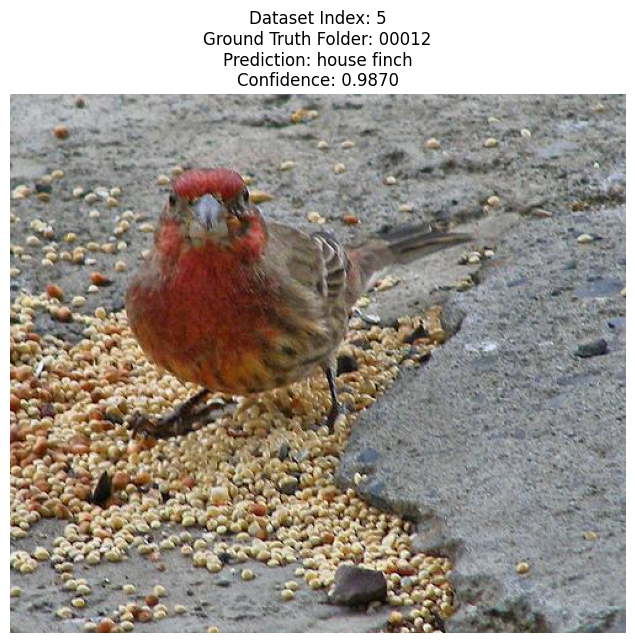


DATASET INDEX: 2
Image file: 606843467581765.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00013/606843467581765.jpg
Folder name (GT): 00013
Dataset label index: 2

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 13
Predicted label: junco
Confidence: 0.9983

TOP-5 PREDICTIONS
--------------------------------------------------
1. junco (Class index: 13, Confidence: 0.9983)
2. chickadee (Class index: 19, Confidence: 0.0008)
3. magpie (Class index: 18, Confidence: 0.0003)
4. bulbul (Class index: 16, Confidence: 0.0003)
5. brambling (Class index: 10, Confidence: 0.0002)


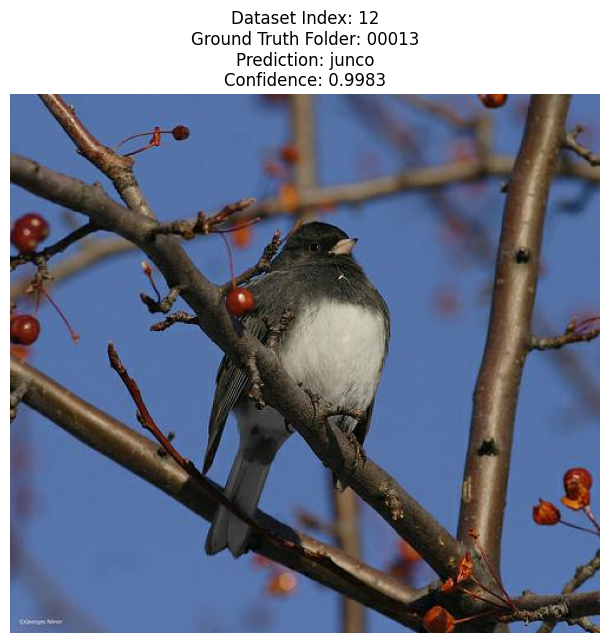


DATASET INDEX: 4
Image file: 7374881593269804.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00015/7374881593269804.jpg
Folder name (GT): 00015
Dataset label index: 4

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 15
Predicted label: robin
Confidence: 0.9992

TOP-5 PREDICTIONS
--------------------------------------------------
1. robin (Class index: 15, Confidence: 0.9992)
2. brambling (Class index: 10, Confidence: 0.0003)
3. jacamar (Class index: 95, Confidence: 0.0002)
4. quail (Class index: 85, Confidence: 0.0001)
5. great grey owl (Class index: 24, Confidence: 0.0000)


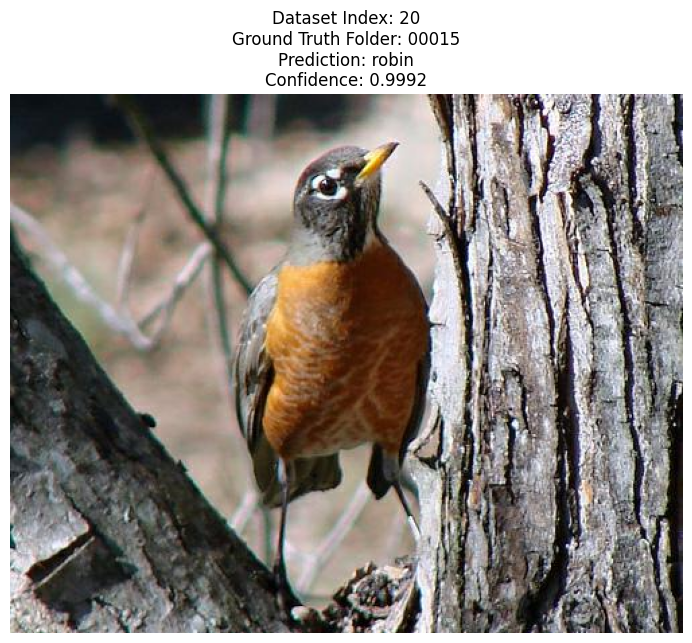

In [14]:
# Positions of the images in the dataset that we will study in detail
SELECTED_INDICES = [0, 5, 12, 20]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
# Safety check: skip indices that do not exist
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 75)
  print(f"DATASET INDEX: {result['dataset_index']}")
  print("=" * 75)
  print(f"Image file: {result['file_name']}")
  print(f"Full path: {result['image_path']}")
  print(f"Folder name (GT): {result['folder_name']}") # GT = ground truth
  print(f"Dataset label index: {result['true_label_idx']}")
  print("\nTOP-1 PREDICTION")
  print("-" * 50)
  print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
  print(f"Predicted label: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
  print("\nTOP-5 PREDICTIONS")
  print("-" * 50)
  for prediction in result["top5"]:
    print(
      f"{prediction['rank']}. "
      f"{prediction['label']} "
      f"(Class index: {prediction['class_index']}, "
      f"Confidence: {prediction['confidence']:.4f})"
    )
# Load the original (un-normalised) image for display
  img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
  plt.figure(figsize=(13, 7))
  plt.imshow(img)
  plt.title(
    f"Dataset Index: {selected_idx}\n"
    f"Ground Truth Folder: {result['folder_name']}\n"
    f"Prediction: {result['pred_label']}\n"
    f"Confidence: {result['confidence']:.4f}",
    fontsize=12
  )
  plt.axis("off")
  plt.show()

XAI methods:

In [15]:
# ============================================================
# DENSENET121: TORCHCAM
# Methods: Grad-CAM++ and Score-CAM
# Metrics:
# Insertion AUC
# Deletion AUC
# ============================================================
model.eval()
# ------------------------------------------------------------
# Target layer
# ------------------------------------------------------------

# The CAM is computed from this layer's feature maps. denseblock4 is the
# last convolutional block, so it holds the most class-specific information
# (its spatial size is only 7x7, which is why heatmaps look coarse).
target_layer = model.features.denseblock4
# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
# Same resize + crop as before but WITHOUT normalisation,
# so the picture looks natural when we overlay the heatmap on it
display_transform = transforms.Compose([
transforms.Resize(256),
transforms.CenterCrop(224)
])
EVAL_STEPS = 20 # steps used to build the insertion/deletion curve
METRIC_BATCH_SIZE = 32 # images processed together in the metric
SCORECAM_BATCH_SIZE = 16 # feature maps processed together by Score-CAM
SELECTED_INDICES = [0, 5, 12, 20]
# Store individual results (one row per image per method)
evaluation_results = []
# ------------------------------------------------------------
# CAM methods
# ------------------------------------------------------------
# Dictionary: display name -> TorchCAM class
cam_methods = {
"Grad-CAM++": GradCAMpp, # gradient-based method
"Score-CAM": ScoreCAM # gradient-free, score-based method
}

Generating explanations and evaluating them:


IMAGE INDEX: 0
FILE: 4688179944691877.jpg
PREDICTION: goldfish
CONFIDENCE: 0.5454

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.3920
Deletion AUC: 0.0705
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.2927
Deletion AUC: 0.0706
--------------------------------------------------


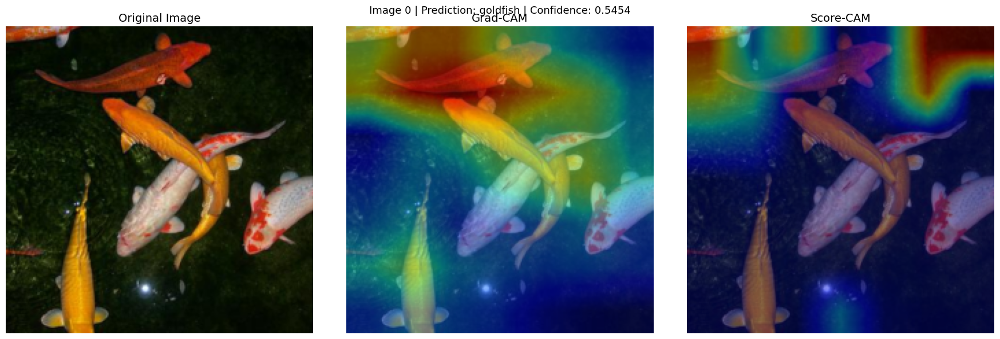


IMAGE INDEX: 5
FILE: 3294314705554.jpg
PREDICTION: bulbul
CONFIDENCE: 0.5884

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.6335
Deletion AUC: 0.0237
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.5655
Deletion AUC: 0.0276
--------------------------------------------------


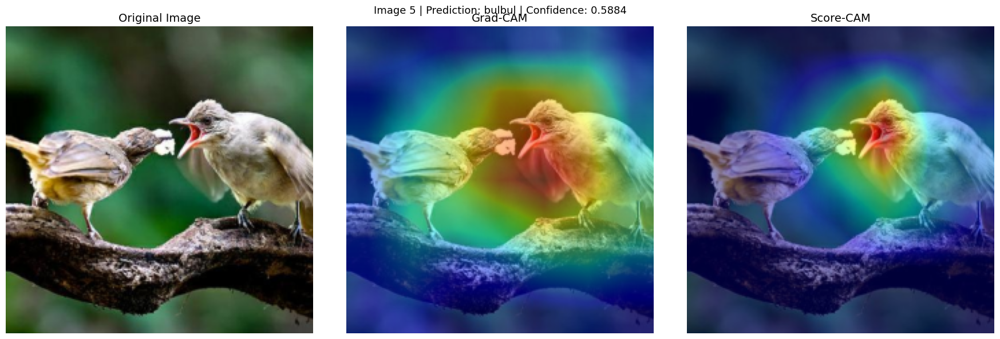


IMAGE INDEX: 12
FILE: 546996126745167.jpg
PREDICTION: sea lion
CONFIDENCE: 0.9999

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.7919
Deletion AUC: 0.2844
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.8201
Deletion AUC: 0.5024
--------------------------------------------------


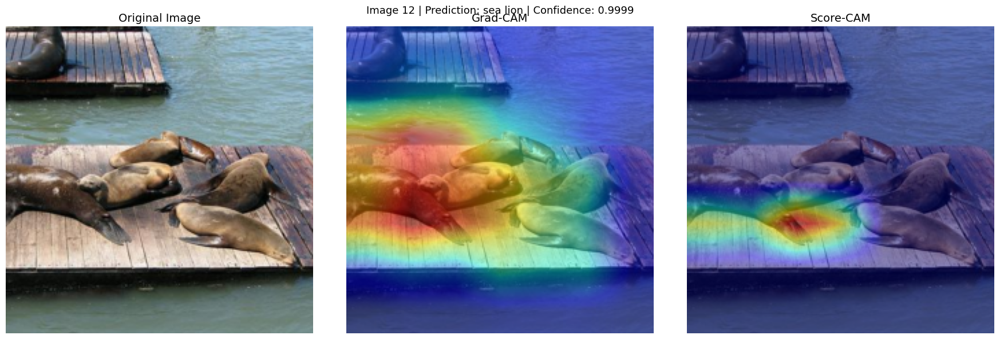


IMAGE INDEX: 20
FILE: 6019817989449685.jpg
PREDICTION: Tibetan terrier
CONFIDENCE: 0.3311

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.2694
Deletion AUC: 0.0261
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.0682
Deletion AUC: 0.0570
--------------------------------------------------


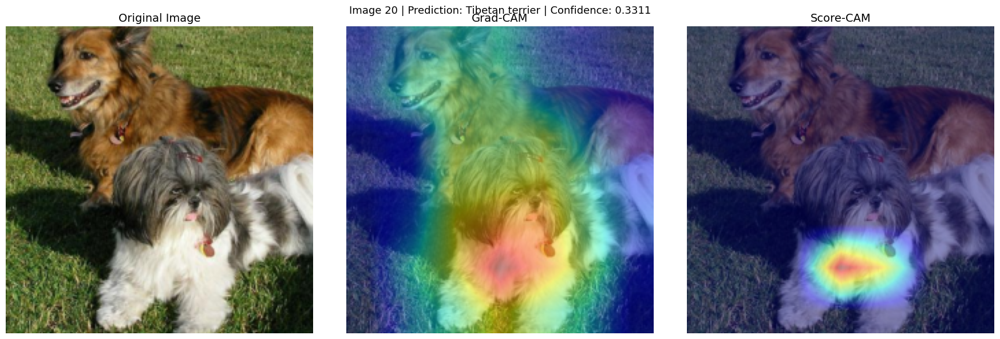

In [18]:
# ============================================================
# RUN BOTH METHODS
# ============================================================
# Converts raw model scores (logits) into probabilities that sum to 1.
# The metric uses this to track the class probability as pixels change.
logits_fn = partial(torch.softmax, dim=-1)
for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 85)
  print(f"IMAGE INDEX: {selected_idx}")
  print(f"FILE: {result['file_name']}")
  print(f"PREDICTION: {result['pred_label']}")
  print(f"CONFIDENCE: {result['confidence']:.4f}")
# --------------------------------------------------------
# Load original image
# --------------------------------------------------------
  original_img = Image.open(
    result["image_path"]
  ).convert("RGB")
# Resize/crop for display and scale pixel values to the range [0, 1]
  rgb_img = display_transform(original_img)
  rgb_img = np.asarray(
    rgb_img
  ).astype(np.float32) / 255.0
# --------------------------------------------------------
# Prepare model input
# --------------------------------------------------------
# Normalised tensor of this image, with a batch dimension added: [1, 3, 224, 224]
  input_tensor, _ = dataset[selected_idx]
  input_tensor = input_tensor.unsqueeze(0).to(device)
# We explain the class the model PREDICTED (not the ground truth)
  class_idx = result["pred_class_idx"]
# Store CAMs for current image
  image_cams = {}
# --------------------------------------------------------
# RUN BOTH METHODS
# --------------------------------------------------------
  for method_name, method_class in cam_methods.items():
# Score-CAM needs an extra batch_size argument; Grad-CAM++ does not
    if method_name == "Score-CAM":
      cam_context = method_class(
        model=model,
        target_layer=target_layer,
        batch_size=SCORECAM_BATCH_SIZE
      )
    else:
      cam_context = method_class(
        model=model,
        target_layer=target_layer
      )
# "with" registers the hooks on the layer and removes them afterwards
    with cam_context as cam_extractor:
      model.zero_grad(set_to_none=True)
# Gradients must be enabled here (Grad-CAM++ depends on them)
      with torch.enable_grad():
        scores = model(input_tensor)
# Compute the class activation map for the predicted class
        cams = cam_extractor(
          class_idx=class_idx,
          scores=scores
        )
      cam = cams[0][0].detach().cpu()
# Upsample CAM from 7x7 to 224x224 for visualization
      cam = torch.nn.functional.interpolate(
        cam.unsqueeze(0).unsqueeze(0),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
      )[0, 0].numpy()
# =================================================
# INSERTION AND DELETION AUC
# =================================================
# baseline=None -> a blank (zero) image is used as the starting point
      deletion_insertion_metric = DeletionInsertionMetric(
        cam_extractor,
        logits_fn=logits_fn,
        steps=EVAL_STEPS,
        batch_size=METRIC_BATCH_SIZE,
        baseline=None
      )
      deletion_insertion_metric.update(
        input_tensor,
        class_idx=class_idx
      )
      deletion_insertion_scores = (
        deletion_insertion_metric.summary()
      )
      insertion_auc = (
        deletion_insertion_scores["insertion_auc"]
      )
      deletion_auc = (
        deletion_insertion_scores["deletion_auc"]
      )
# =================================================
# STORE RESULTS
# =================================================
      evaluation_results.append({
        "Dataset Index": selected_idx,
        "File Name": result["file_name"],
        "Ground Truth": result["folder_name"],
        "Predicted Class": result["pred_label"],
        "Class Index": class_idx,
        "Original Confidence": result["confidence"],
        "Method": method_name,
        "Insertion AUC": insertion_auc,
        "Deletion AUC": deletion_auc
      })
# Store CAM using actual method name
      image_cams[method_name] = cam
# =================================================
# DISPLAY METRICS
# =================================================
      print(f"\n{method_name} EVALUATION METRICS")
      print("-" * 50)
      print(f"Insertion AUC: {insertion_auc:.4f}")
      print(f"Deletion AUC: {deletion_auc:.4f}")
      print("-" * 50)
# ========================================================
# IDENTIFY ACTUAL METHOD NAMES
# ========================================================
# Look the CAMs up by name (robust to small naming differences)
  gradcam_name = next(
    name for name in image_cams
    if "gradcam" in name.lower().replace("-", "").replace("_", "")
    and "score" not in name.lower()
  )
  scorecam_name = next(
    name for name in image_cams
    if "scorecam" in name.lower().replace("-", "").replace("_", "")
  )
# ========================================================
# DISPLAY: ORIGINAL | GRAD-CAM | SCORE-CAM
# ========================================================
  fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
  )
# LEFT: ORIGINAL
  axes[0].imshow(rgb_img)
  axes[0].set_title(
    "Original Image",
    fontsize=14
  )
# CENTRE: GRAD-CAM (heatmap drawn semi-transparent over the image)
  axes[1].imshow(rgb_img)
  axes[1].imshow(
    image_cams[gradcam_name],
    cmap="jet", # red = most important, blue = least important
    alpha=0.45 # transparency of the heatmap
  )
  axes[1].set_title(
    "Grad-CAM",
    fontsize=14
  )
# RIGHT: SCORE-CAM
  axes[2].imshow(rgb_img)
  axes[2].imshow(
    image_cams[scorecam_name],
    cmap="jet",
    alpha=0.45
  )
  axes[2].set_title(
    "Score-CAM",
    fontsize=14
  )
  for ax in axes:
    ax.axis("off")
  fig.suptitle(
    f"Image {selected_idx} | "
    f"Prediction: {result['pred_label']} | "
    f"Confidence: {result['confidence']:.4f}",
    fontsize=13
  )
  plt.tight_layout()
  plt.show()

Task: I am going to be using ResNet-50 and VGG-16 as my other two acrchitecture to perfrom GradCAM++ and ScoreCAM classificaton on given image set.

My third metric of evaluation will be a `bounding box localization`

Loading ResNet-50:

In [20]:
#import resnet:
from torchvision.models import resnet50, ResNet50_Weights
# ------------------------------------------------------------
# Load pretrained ResNet50
# ------------------------------------------------------------
# Weights trained on ImageNet-1K (1000 everyday object classes)
weights = ResNet50_Weights.IMAGENET1K_V1
# Build the network, load the weights and move it to the GPU/CPU
model = resnet50(weights=weights).to(device)
# eval() switches off dropout / batch-norm updates -> deterministic predictions
model.eval()
print("ResNet50 classifier loaded")
# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------
print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: ResNet50")
print("Architecture: Convolutional Neural Network")
# The final linear layer has one output per ImageNet class
print("Number of output classes:", model.fc.out_features)

ResNet50 classifier loaded

MODEL CONFIGURATION
--------------------------------------------------
Model: ResNet50
Architecture: Convolutional Neural Network
Number of output classes: 1000


Predictions:

In [22]:
# Inference on the complete dataset
results = [] # will hold one dictionary per image
model.eval()
# no_grad() -> we only predict here, so gradients are not needed (saves memory)
with torch.no_grad():
  for idx, (images, labels) in enumerate(dataloader):
    images = images.to(device)
# Original image information
    img_path, true_label_idx = dataset.samples[idx]
    folder_name = os.path.basename(os.path.dirname(img_path))
    file_name = os.path.basename(img_path)
# Forward pass: image -> 1000 raw scores (logits)
    logits = model(images)
# Softmax turns the logits into probabilities
    probs = torch.softmax(logits, dim=-1)
# Top-1 prediction = class with the highest probability
    pred_class_idx = torch.argmax(probs, dim=-1).item()
    confidence = probs[0, pred_class_idx].item()
    pred_label = id2label[pred_class_idx]
# Top-5 predictions = five most likely classes
    top5_probs, top5_indices = torch.topk(
      probs,
      k=5,
      dim=-1
    )
    top5_predictions = []
    for rank in range(5):
      class_idx = top5_indices[0, rank].item()
      class_prob = top5_probs[0, rank].item()
      class_label = id2label[class_idx]
      top5_predictions.append({
        "rank": rank + 1,
        "class_index": class_idx,
        "label": class_label,
        "confidence": class_prob
      })
# Store all results for later use
    results.append({
      "dataset_index": idx,
      "image_path": img_path,
      "file_name": file_name,
      "folder_name": folder_name,
      "true_label_idx": true_label_idx,
      "pred_class_idx": pred_class_idx,
      "pred_label": pred_label,
      "confidence": confidence,
      "top5": top5_predictions
    })
# Progress message every 10 images and at the very end
    if (idx + 1) % 10 == 0 or (idx + 1) == len(dataset):
      print(f"Processed {idx + 1}/{len(dataset)} images")

print("\nInference completed.")
print(f"Total images processed: {len(results)}")

Processed 10/41 images
Processed 20/41 images
Processed 30/41 images
Processed 40/41 images
Processed 41/41 images

Inference completed.
Total images processed: 41


Prediction on selected images(same images for each model):


DATASET INDEX: 0
Image file: 4688179944691877.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00001/4688179944691877.jpg
Folder name (GT): 00001
Dataset label index: 0

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 1
Predicted label: goldfish
Confidence: 0.5528

TOP-5 PREDICTIONS
--------------------------------------------------
1. goldfish (Class index: 1, Confidence: 0.5528)
2. sea slug (Class index: 115, Confidence: 0.1086)
3. starfish (Class index: 327, Confidence: 0.0814)
4. eft (Class index: 27, Confidence: 0.0651)
5. stinkhorn (Class index: 994, Confidence: 0.0350)


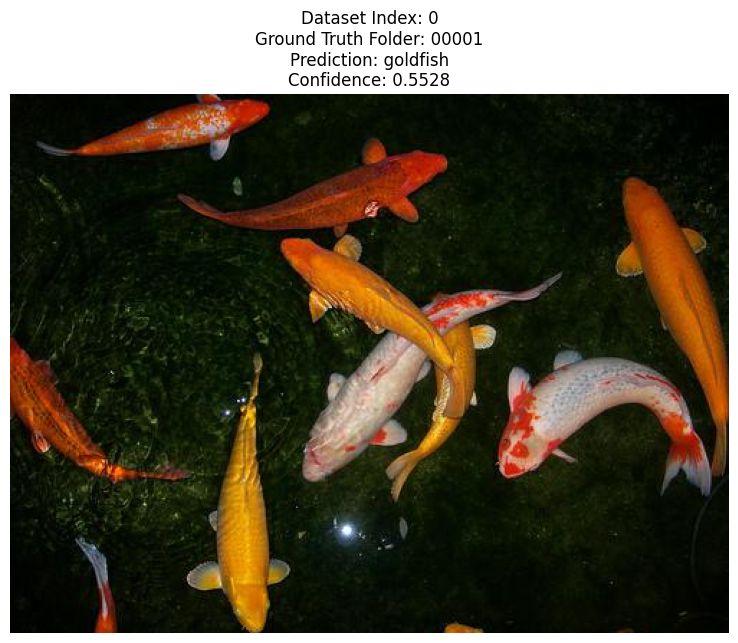


DATASET INDEX: 5
Image file: 3294314705554.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00016/3294314705554.jpg
Folder name (GT): 00016
Dataset label index: 5

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 16
Predicted label: bulbul
Confidence: 0.8319

TOP-5 PREDICTIONS
--------------------------------------------------
1. bulbul (Class index: 16, Confidence: 0.8319)
2. hummingbird (Class index: 94, Confidence: 0.0586)
3. hornbill (Class index: 93, Confidence: 0.0376)
4. bee eater (Class index: 92, Confidence: 0.0211)
5. jacamar (Class index: 95, Confidence: 0.0108)


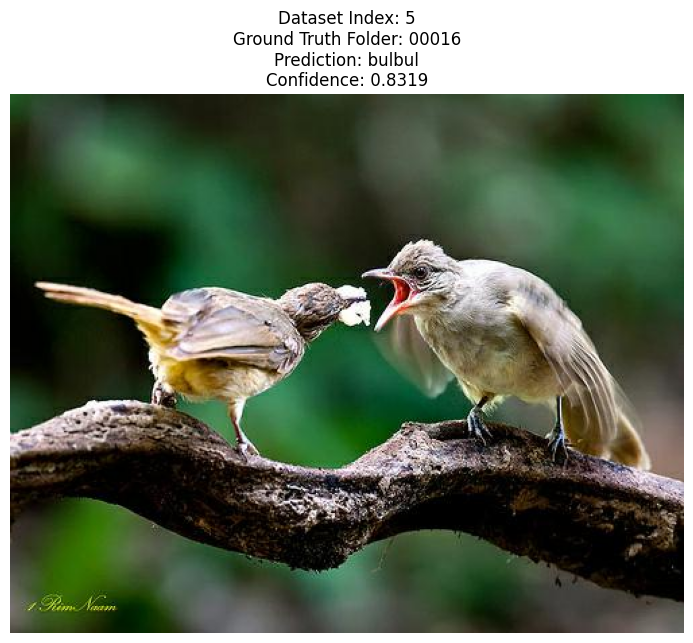


DATASET INDEX: 12
Image file: 546996126745167.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00150/546996126745167.jpg
Folder name (GT): 00150
Dataset label index: 12

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 150
Predicted label: sea lion
Confidence: 0.9994

TOP-5 PREDICTIONS
--------------------------------------------------
1. sea lion (Class index: 150, Confidence: 0.9994)
2. otter (Class index: 360, Confidence: 0.0004)
3. weasel (Class index: 356, Confidence: 0.0000)
4. black-footed ferret (Class index: 359, Confidence: 0.0000)
5. pier (Class index: 718, Confidence: 0.0000)


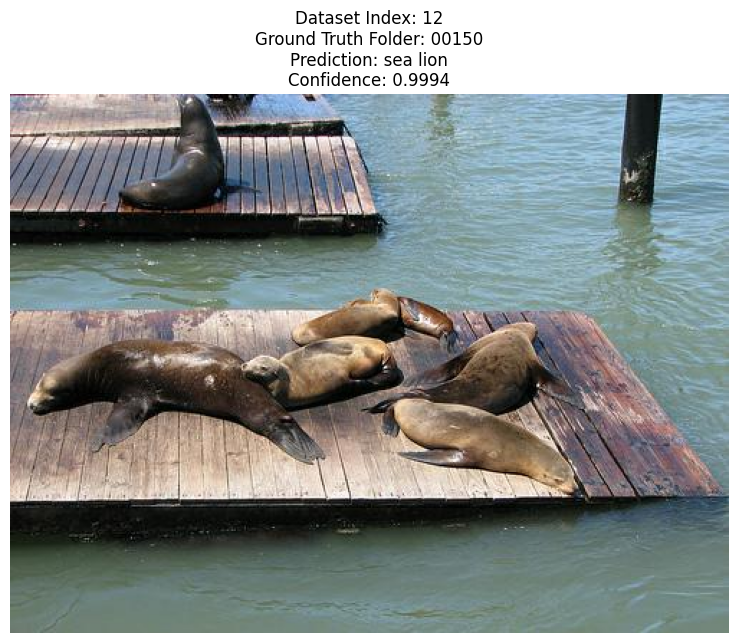


DATASET INDEX: 20
Image file: 6019817989449685.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00155/6019817989449685.jpg
Folder name (GT): 00155
Dataset label index: 17

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 200
Predicted label: Tibetan terrier
Confidence: 0.1163

TOP-5 PREDICTIONS
--------------------------------------------------
1. Tibetan terrier (Class index: 200, Confidence: 0.1163)
2. Australian terrier (Class index: 193, Confidence: 0.1141)
3. Shih-Tzu (Class index: 155, Confidence: 0.0826)
4. Lhasa (Class index: 204, Confidence: 0.0688)
5. collie (Class index: 231, Confidence: 0.0493)


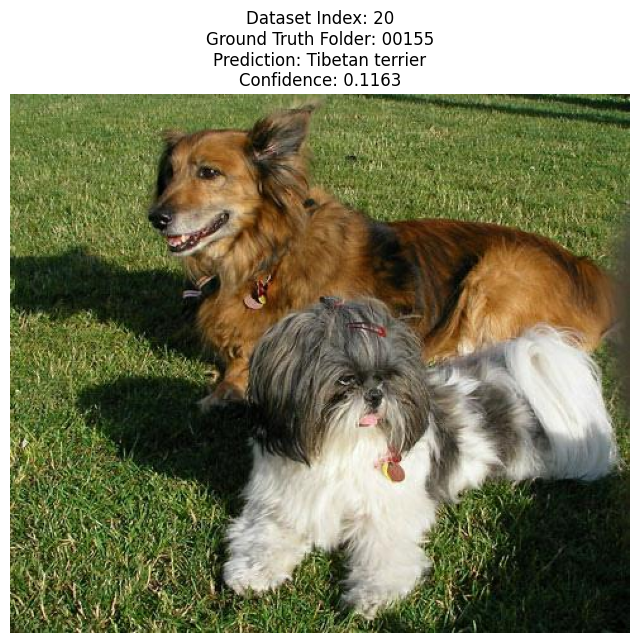

In [23]:
# Positions of the images in the dataset that we will study in detail
SELECTED_INDICES = [0, 5, 12, 20]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
# Safety check: skip indices that do not exist
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 75)
  print(f"DATASET INDEX: {result['dataset_index']}")
  print("=" * 75)
  print(f"Image file: {result['file_name']}")
  print(f"Full path: {result['image_path']}")
  print(f"Folder name (GT): {result['folder_name']}") # GT = ground truth
  print(f"Dataset label index: {result['true_label_idx']}")
  print("\nTOP-1 PREDICTION")
  print("-" * 50)
  print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
  print(f"Predicted label: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
  print("\nTOP-5 PREDICTIONS")
  print("-" * 50)
  for prediction in result["top5"]:
    print(
      f"{prediction['rank']}. "
      f"{prediction['label']} "
      f"(Class index: {prediction['class_index']}, "
      f"Confidence: {prediction['confidence']:.4f})"
    )
# Load the original (un-normalised) image for display
  img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
  plt.figure(figsize=(13, 7))
  plt.imshow(img)
  plt.title(
    f"Dataset Index: {selected_idx}\n"
    f"Ground Truth Folder: {result['folder_name']}\n"
    f"Prediction: {result['pred_label']}\n"
    f"Confidence: {result['confidence']:.4f}",
    fontsize=12
  )
  plt.axis("off")
  plt.show()

XAI methods on ResNet50:

In [25]:
# ============================================================
# ResNet50: TORCHCAM
# Methods: Grad-CAM++ and Score-CAM
# Metrics:
# - Insertion AUC
# - Deletion AUC
# - Bounding Box Localization (CAM Binarization & Bounding Box extraction)
# ============================================================
model.eval()
# ------------------------------------------------------------
# Target layer
# ------------------------------------------------------------

# The CAM is computed from this layer's feature maps. layer4 is the
# last convolutional block, so it holds the most class-specific information
target_layer = model.layer4
# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
# Same resize + crop as before but WITHOUT normalisation,
# so the picture looks natural when we overlay the heatmap on it
display_transform = transforms.Compose([
transforms.Resize(256),
transforms.CenterCrop(224)
])
EVAL_STEPS = 20 # steps used to build the insertion/deletion curve
METRIC_BATCH_SIZE = 32 # images processed together in the metric
SCORECAM_BATCH_SIZE = 16 # feature maps processed together by Score-CAM
SELECTED_INDICES = [0, 5, 12, 20]
# Threshold ratio for bounding box extraction (e.g. 0.2 means keep pixels >= 20% of max intensity)
BBOX_THRESHOLD = 0.2
# Store individual results (one row per image per method)
evaluation_results = []
# ------------------------------------------------------------
# CAM methods
# ------------------------------------------------------------
# Dictionary: display name -> TorchCAM class
cam_methods = {
"Grad-CAM++": GradCAMpp, # gradient-based method
"Score-CAM": ScoreCAM # gradient-free, score-based method
}

Final Predictions using GradCAM++ and ScoreCAM:


IMAGE INDEX: 0
FILE: 4688179944691877.jpg
PREDICTION: goldfish
CONFIDENCE: 0.5528

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.3717
Deletion AUC: 0.1307
Estimated Bounding Box [x, y, w, h]: [0, 0, 223, 223]
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.5430
Deletion AUC: 0.1012
Estimated Bounding Box [x, y, w, h]: [0, 0, 223, 223]
--------------------------------------------------


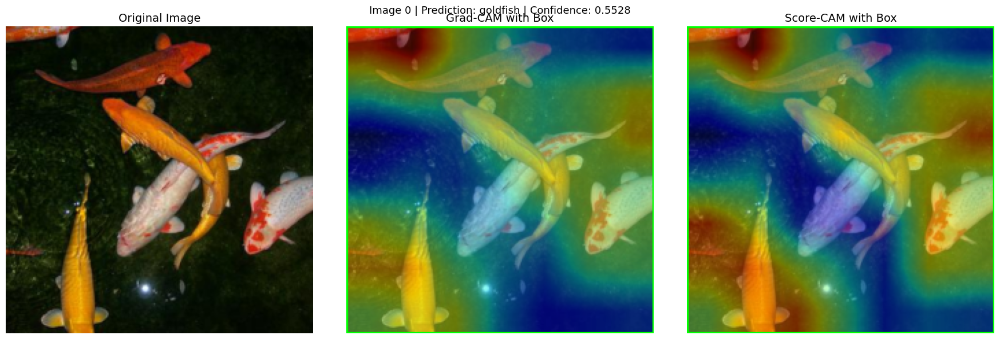


IMAGE INDEX: 5
FILE: 3294314705554.jpg
PREDICTION: bulbul
CONFIDENCE: 0.8319

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.7061
Deletion AUC: 0.0388
Estimated Bounding Box [x, y, w, h]: [0, 24, 223, 199]
--------------------------------------------------


KeyboardInterrupt: 

In [27]:
# ============================================================
# RUN BOTH METHODS WITH PERFORMANCE OPTIMIZATIONS & BBOX LOCALIZATION
# ============================================================
import matplotlib.patches as patches

# Converts raw model scores (logits) into probabilities that sum to 1.
# The metric uses this to track the class probability as pixels change.
logits_fn = partial(torch.softmax, dim=-1)
BBOX_THRESHOLD = 0.2

for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 85)
  print(f"IMAGE INDEX: {selected_idx}")
  print(f"FILE: {result['file_name']}")
  print(f"PREDICTION: {result['pred_label']}")
  print(f"CONFIDENCE: {result['confidence']:.4f}")
# --------------------------------------------------------
# Load original image
# --------------------------------------------------------
  original_img = Image.open(
    result["image_path"]
  ).convert("RGB")
# Resize/crop for display and scale pixel values to the range [0, 1]
  rgb_img = display_transform(original_img)
  rgb_img = np.asarray(
    rgb_img
  ).astype(np.float32) / 255.0
# --------------------------------------------------------
# Prepare model input
# --------------------------------------------------------
# Normalised tensor of this image, with a batch dimension added: [1, 3, 224, 224]
  input_tensor, _ = dataset[selected_idx]
  input_tensor = input_tensor.unsqueeze(0).to(device)
# We explain the class the model PREDICTED (not the ground truth)
  class_idx = result["pred_class_idx"]
# Store CAMs and extracted bounding boxes for current image
  image_cams = {}
  image_bboxes = {}
# --------------------------------------------------------
# RUN BOTH METHODS
# --------------------------------------------------------
  for method_name, method_class in cam_methods.items():
# Score-CAM needs an extra batch_size argument; Grad-CAM++ does not
    if method_name == "Score-CAM":
      cam_context = method_class(
        model=model,
        target_layer=target_layer,
        batch_size=SCORECAM_BATCH_SIZE
      )
    else:
      cam_context = method_class(
        model=model,
        target_layer=target_layer
      )
# "with" registers the hooks on the layer and removes them afterwards
    with cam_context as cam_extractor:
      model.zero_grad(set_to_none=True)
# Gradients must be enabled here (Grad-CAM++ depends on them)
      with torch.enable_grad():
        scores = model(input_tensor)
# Compute the class activation map for the predicted class
        cams = cam_extractor(
          class_idx=class_idx,
          scores=scores
        )
      cam = cams[0][0].detach().cpu()
# Upsample CAM from 7x7 to 224x224 for visualization
      cam = torch.nn.functional.interpolate(
        cam.unsqueeze(0).unsqueeze(0),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
      )[0, 0].numpy()
# =================================================
# INSERTION AND DELETION AUC
# =================================================
# baseline=None -> a blank (zero) image is used as the starting point
      deletion_insertion_metric = DeletionInsertionMetric(
        cam_extractor,
        logits_fn=logits_fn,
        steps=EVAL_STEPS,
        batch_size=METRIC_BATCH_SIZE,
        baseline=None
      )
      deletion_insertion_metric.update(
        input_tensor,
        class_idx=class_idx
      )
      deletion_insertion_scores = (
        deletion_insertion_metric.summary()
      )
      insertion_auc = (
        deletion_insertion_scores["insertion_auc"]
      )
      deletion_auc = (
        deletion_insertion_scores["deletion_auc"]
      )
# =================================================
# BOUNDING BOX LOCALIZATION
# =================================================
# Normalize CAM to [0, 1] to apply thresholding robustly
      cam_min, cam_max = cam.min(), cam.max()
      norm_cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
# Binarize using configuration threshold
      binary_mask = norm_cam >= BBOX_THRESHOLD
      y_indices, x_indices = np.where(binary_mask)
      if len(x_indices) > 0 and len(y_indices) > 0:
        min_x, max_x = int(x_indices.min()), int(x_indices.max())
        min_y, max_y = int(y_indices.min()), int(y_indices.max())
        bbox = [min_x, min_y, max_x - min_x, max_y - min_y] # [x, y, width, height]
      else:
        bbox = [0, 0, 224, 224]
# =================================================
# STORE RESULTS
# =================================================
      evaluation_results.append({
        "Dataset Index": selected_idx,
        "File Name": result["file_name"],
        "Ground Truth": result["folder_name"],
        "Predicted Class": result["pred_label"],
        "Class Index": class_idx,
        "Original Confidence": result["confidence"],
        "Method": method_name,
        "Insertion AUC": insertion_auc,
        "Deletion AUC": deletion_auc,
        "BBox [x, y, w, h]": bbox
      })
# Store CAM and bounding box using actual method name
      image_cams[method_name] = cam
      image_bboxes[method_name] = bbox
# =================================================
# DISPLAY METRICS
# =================================================
      print(f"\n{method_name} EVALUATION METRICS")
      print("-" * 50)
      print(f"Insertion AUC: {insertion_auc:.4f}")
      print(f"Deletion AUC: {deletion_auc:.4f}")
      print(f"Estimated Bounding Box [x, y, w, h]: {bbox}")
      print("-" * 50)
# ========================================================
# IDENTIFY ACTUAL METHOD NAMES
# ========================================================
# Look the CAMs up by name (robust to small naming differences)
  gradcam_name = next(
    name for name in image_cams
    if "gradcam" in name.lower().replace("-", "").replace("_", "")
    and "score" not in name.lower()
  )
  scorecam_name = next(
    name for name in image_cams
    if "scorecam" in name.lower().replace("-", "").replace("_", "")
  )
# ========================================================
# DISPLAY: ORIGINAL | GRAD-CAM | SCORE-CAM WITH BOUNDING BOXES
# ========================================================
  fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
  )
# LEFT: ORIGINAL
  axes[0].imshow(rgb_img)
  axes[0].set_title(
    "Original Image",
    fontsize=14
  )
# CENTRE: GRAD-CAM (heatmap drawn semi-transparent over the image + BBox overlay)
  axes[1].imshow(rgb_img)
  axes[1].imshow(
    image_cams[gradcam_name],
    cmap="jet", # red = most important, blue = least important
    alpha=0.45 # transparency of the heatmap
  )
  gc_bbox = image_bboxes[gradcam_name]
  rect_gc = patches.Rectangle((gc_bbox[0], gc_bbox[1]), gc_bbox[2], gc_bbox[3], linewidth=2.5, edgecolor='lime', facecolor='none')
  axes[1].add_patch(rect_gc)
  axes[1].set_title(
    "Grad-CAM with Box",
    fontsize=14
  )
# RIGHT: SCORE-CAM (heatmap + BBox overlay)
  axes[2].imshow(rgb_img)
  axes[2].imshow(
    image_cams[scorecam_name],
    cmap="jet",
    alpha=0.45
  )
  sc_bbox = image_bboxes[scorecam_name]
  rect_sc = patches.Rectangle((sc_bbox[0], sc_bbox[1]), sc_bbox[2], sc_bbox[3], linewidth=2.5, edgecolor='lime', facecolor='none')
  axes[2].add_patch(rect_sc)
  axes[2].set_title(
    "Score-CAM with Box",
    fontsize=14
  )
  for ax in axes:
    ax.axis("off")
  fig.suptitle(
    f"Image {selected_idx} | "
    f"Prediction: {result['pred_label']} | "
    f"Confidence: {result['confidence']:.4f}",
    fontsize=13
  )
  plt.tight_layout()
  plt.show()

Load VGG-16:

In [29]:
#import vgg16:
from torchvision.models import vgg16, VGG16_Weights
# ------------------------------------------------------------
# Load pretrained VGG16
# ------------------------------------------------------------
# Weights trained on ImageNet-1K (1000 everyday object classes)
weights = VGG16_Weights.IMAGENET1K_V1
# Build the network, load the weights and move it to the GPU/CPU
model = vgg16(weights=weights).to(device)
# eval() switches off dropout / batch-norm updates -> deterministic predictions
model.eval()
print("VGG16 classifier loaded")
# ------------------------------------------------------------
# Model configuration
# ------------------------------------------------------------
print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Model: VGG16")
print("Architecture: Convolutional Neural Network")
print("Number of Dense Blocks:", len(model.features.denseblock.__dict__) if False else 3)
# The final linear layer (Linear) is the 7th element (index 6) in the sequential classifier block
print("Number of output classes:", model.classifier[6].out_features)

VGG16 classifier loaded

MODEL CONFIGURATION
--------------------------------------------------
Model: VGG16
Architecture: Convolutional Neural Network
Number of Dense Blocks: 3
Number of output classes: 1000


Inference:

In [30]:
# Inference on the complete dataset
results = [] # will hold one dictionary per image
model.eval()
# no_grad() -> we only predict here, so gradients are not needed (saves memory)
with torch.no_grad():
  for idx, (images, labels) in enumerate(dataloader):
    images = images.to(device)
# Original image information
    img_path, true_label_idx = dataset.samples[idx]
    folder_name = os.path.basename(os.path.dirname(img_path))
    file_name = os.path.basename(img_path)
# Forward pass: image -> 1000 raw scores (logits)
    logits = model(images)
# Softmax turns the logits into probabilities
    probs = torch.softmax(logits, dim=-1)
# Top-1 prediction = class with the highest probability
    pred_class_idx = torch.argmax(probs, dim=-1).item()
    confidence = probs[0, pred_class_idx].item()
    pred_label = id2label[pred_class_idx]
# Top-5 predictions = five most likely classes
    top5_probs, top5_indices = torch.topk(
      probs,
      k=5,
      dim=-1
    )
    top5_predictions = []
    for rank in range(5):
      class_idx = top5_indices[0, rank].item()
      class_prob = top5_probs[0, rank].item()
      class_label = id2label[class_idx]
      top5_predictions.append({
        "rank": rank + 1,
        "class_index": class_idx,
        "label": class_label,
        "confidence": class_prob
      })
# Store all results for later use
    results.append({
      "dataset_index": idx,
      "image_path": img_path,
      "file_name": file_name,
      "folder_name": folder_name,
      "true_label_idx": true_label_idx,
      "pred_class_idx": pred_class_idx,
      "pred_label": pred_label,
      "confidence": confidence,
      "top5": top5_predictions
    })
# Progress message every 10 images and at the very end
    if (idx + 1) % 10 == 0 or (idx + 1) == len(dataset):
      print(f"Processed {idx + 1}/{len(dataset)} images")

print("\nInference completed.")
print(f"Total images processed: {len(results)}")

Processed 10/41 images
Processed 20/41 images
Processed 30/41 images
Processed 40/41 images
Processed 41/41 images

Inference completed.
Total images processed: 41


Inference on Indivisual images(same indices as last two models):



DATASET INDEX: 0
Image file: 4688179944691877.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00001/4688179944691877.jpg
Folder name (GT): 00001
Dataset label index: 0

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 327
Predicted label: starfish
Confidence: 0.2251

TOP-5 PREDICTIONS
--------------------------------------------------
1. starfish (Class index: 327, Confidence: 0.2251)
2. goldfish (Class index: 1, Confidence: 0.1799)
3. king crab (Class index: 121, Confidence: 0.1524)
4. rock crab (Class index: 119, Confidence: 0.1226)
5. crayfish (Class index: 124, Confidence: 0.0648)


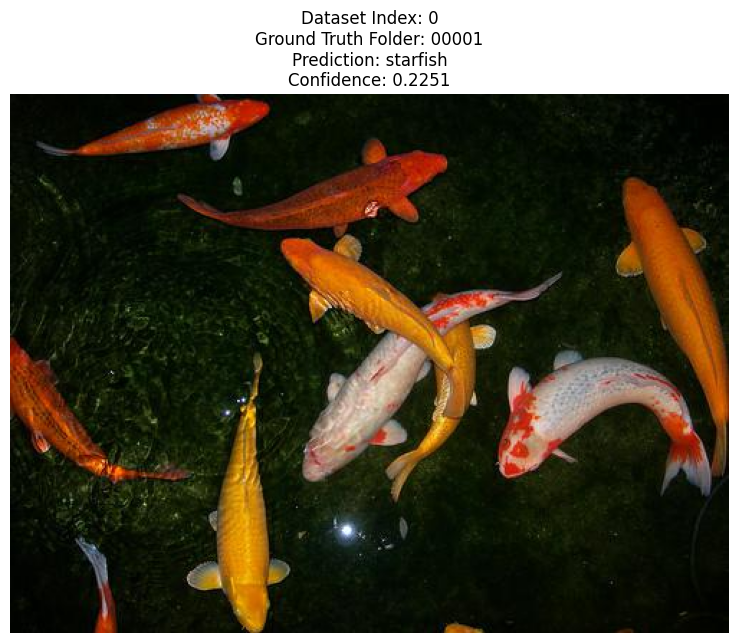


DATASET INDEX: 5
Image file: 3294314705554.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00016/3294314705554.jpg
Folder name (GT): 00016
Dataset label index: 5

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 16
Predicted label: bulbul
Confidence: 0.5073

TOP-5 PREDICTIONS
--------------------------------------------------
1. bulbul (Class index: 16, Confidence: 0.5073)
2. house finch (Class index: 12, Confidence: 0.3862)
3. junco (Class index: 13, Confidence: 0.0288)
4. brambling (Class index: 10, Confidence: 0.0274)
5. hummingbird (Class index: 94, Confidence: 0.0194)


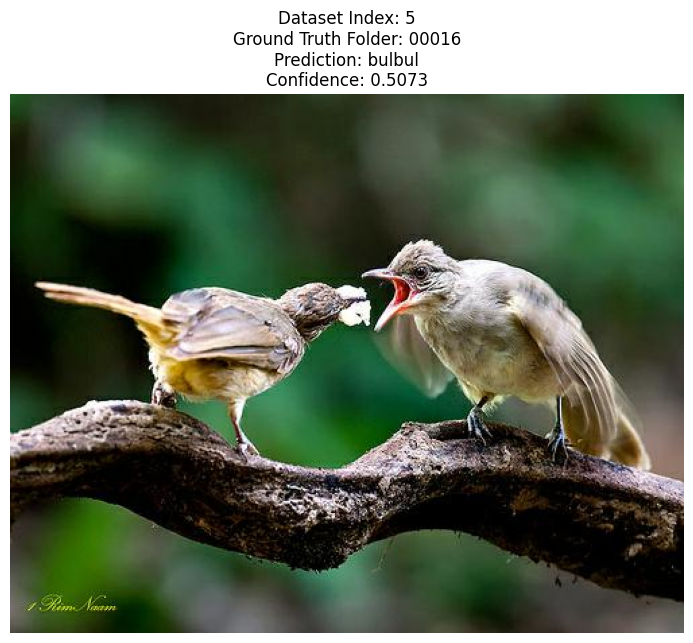


DATASET INDEX: 12
Image file: 546996126745167.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00150/546996126745167.jpg
Folder name (GT): 00150
Dataset label index: 12

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 150
Predicted label: sea lion
Confidence: 0.9953

TOP-5 PREDICTIONS
--------------------------------------------------
1. sea lion (Class index: 150, Confidence: 0.9953)
2. Indian elephant (Class index: 385, Confidence: 0.0028)
3. African elephant (Class index: 386, Confidence: 0.0019)
4. otter (Class index: 360, Confidence: 0.0000)
5. water buffalo (Class index: 346, Confidence: 0.0000)


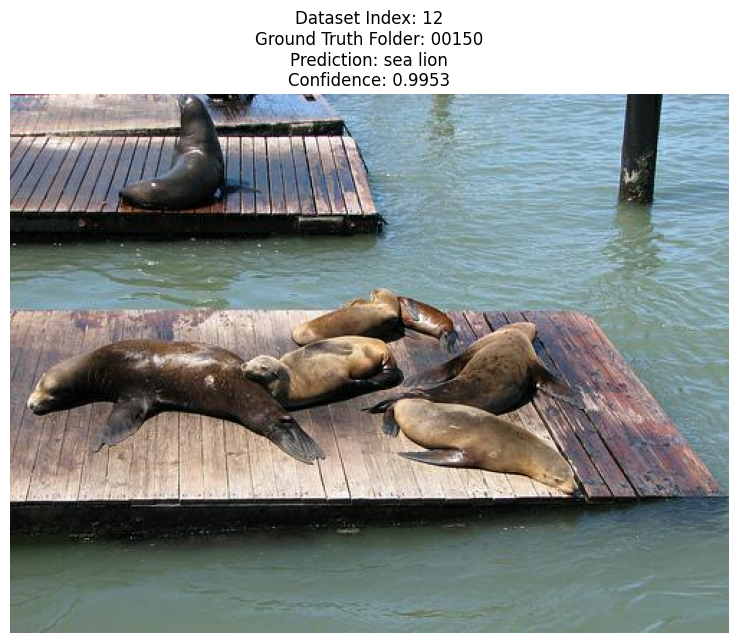


DATASET INDEX: 20
Image file: 6019817989449685.jpg
Full path: /content/drive/MyDrive/CV Lab + Class/data2/00155/6019817989449685.jpg
Folder name (GT): 00155
Dataset label index: 17

TOP-1 PREDICTION
--------------------------------------------------
Predicted ImageNet class index: 154
Predicted label: Pekinese
Confidence: 0.1341

TOP-5 PREDICTIONS
--------------------------------------------------
1. Pekinese (Class index: 154, Confidence: 0.1341)
2. Shih-Tzu (Class index: 155, Confidence: 0.1309)
3. Tibetan terrier (Class index: 200, Confidence: 0.1251)
4. Lhasa (Class index: 204, Confidence: 0.1103)
5. briard (Class index: 226, Confidence: 0.0294)


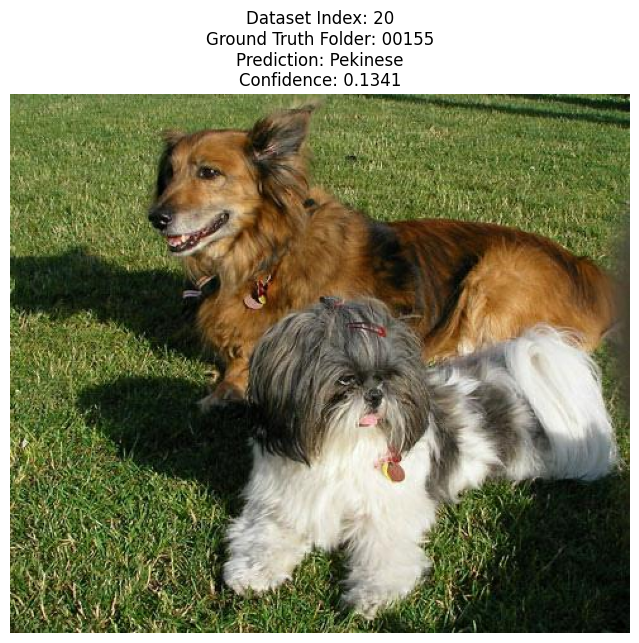

In [31]:
# Positions of the images in the dataset that we will study in detail
SELECTED_INDICES = [0, 5, 12, 20]
# Display selected predictions with original images
for selected_idx in SELECTED_INDICES:
# Safety check: skip indices that do not exist
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 75)
  print(f"DATASET INDEX: {result['dataset_index']}")
  print("=" * 75)
  print(f"Image file: {result['file_name']}")
  print(f"Full path: {result['image_path']}")
  print(f"Folder name (GT): {result['folder_name']}") # GT = ground truth
  print(f"Dataset label index: {result['true_label_idx']}")
  print("\nTOP-1 PREDICTION")
  print("-" * 50)
  print(f"Predicted ImageNet class index: {result['pred_class_idx']}")
  print(f"Predicted label: {result['pred_label']}")
  print(f"Confidence: {result['confidence']:.4f}")
  print("\nTOP-5 PREDICTIONS")
  print("-" * 50)
  for prediction in result["top5"]:
    print(
      f"{prediction['rank']}. "
      f"{prediction['label']} "
      f"(Class index: {prediction['class_index']}, "
      f"Confidence: {prediction['confidence']:.4f})"
    )
# Load the original (un-normalised) image for display
  img = Image.open(result["image_path"]).convert("RGB")
# Display image alongside prediction information
  plt.figure(figsize=(13, 7))
  plt.imshow(img)
  plt.title(
    f"Dataset Index: {selected_idx}\n"
    f"Ground Truth Folder: {result['folder_name']}\n"
    f"Prediction: {result['pred_label']}\n"
    f"Confidence: {result['confidence']:.4f}",
    fontsize=12
  )
  plt.axis("off")
  plt.show()

XAL methods on VGG16:

In [32]:
# ============================================================
# VGG16: TORCHCAM
# Methods: Grad-CAM++ and Score-CAM
# Metrics:
# - Insertion AUC
# - Deletion AUC
# - Bounding Box Localization (CAM Binarization & Bounding Box extraction)
# ============================================================
# Re-load or reference the VGG16 model specifically to ensure 'model' does not reference ResNet50
from torchvision.models import vgg16, VGG16_Weights
model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).to(device)
model.eval()

# ------------------------------------------------------------
# Target layer
# ------------------------------------------------------------
# The CAM is computed from this layer's feature maps.
# For VGG16, we target the last convolutional layer block (features).
target_layer = model.features

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
# Same resize + crop as before but WITHOUT normalisation,
# so the picture looks natural when we overlay the heatmap on it
display_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224)
])

EVAL_STEPS = 20          # steps used to build the insertion/deletion curve
METRIC_BATCH_SIZE = 32   # images processed together in the metric
SCORECAM_BATCH_SIZE = 16 # feature maps processed together by Score-CAM
SELECTED_INDICES = [0, 5, 12, 20]
BBOX_THRESHOLD = 0.2     # Binarization threshold for localization

# Store individual results (one row per image per method)
evaluation_results = []

# ------------------------------------------------------------
# CAM methods
# ------------------------------------------------------------
# Dictionary: display name -> TorchCAM class
cam_methods = {
    "Grad-CAM++": GradCAMpp,
    "Score-CAM": ScoreCAM
}

Final metrics and comparisons on GradCAM++ and ScoreCAM


IMAGE INDEX: 0
FILE: 4688179944691877.jpg
PREDICTION: starfish
CONFIDENCE: 0.2251

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.1233
Deletion AUC: 0.0224
Estimated Bounding Box [x, y, w, h]: [0, 0, 223, 223]
--------------------------------------------------

Score-CAM EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.1774
Deletion AUC: 0.0288
Estimated Bounding Box [x, y, w, h]: [0, 0, 223, 223]
--------------------------------------------------


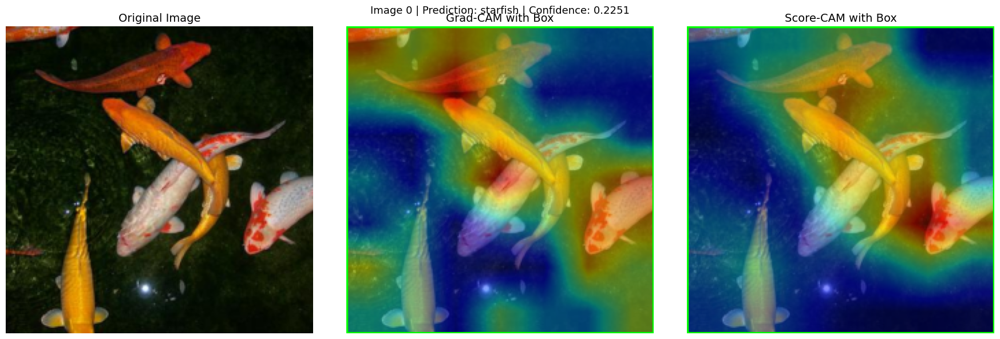


IMAGE INDEX: 5
FILE: 3294314705554.jpg
PREDICTION: bulbul
CONFIDENCE: 0.5073

Grad-CAM++ EVALUATION METRICS
--------------------------------------------------
Insertion AUC: 0.4454
Deletion AUC: 0.0340
Estimated Bounding Box [x, y, w, h]: [0, 27, 223, 162]
--------------------------------------------------


KeyboardInterrupt: 

In [33]:
# ============================================================
# RUN BOTH METHODS WITH INSERTION, DELETION AND BBOX LOCALIZATION
# ============================================================
import matplotlib.patches as patches

# Converts raw model scores (logits) into probabilities that sum to 1.
# The metric uses this to track the class probability as pixels change.
logits_fn = partial(torch.softmax, dim=-1)
for selected_idx in SELECTED_INDICES:
  if selected_idx < 0 or selected_idx >= len(results):
    print(f"Invalid dataset index: {selected_idx}")
    continue
  result = results[selected_idx]
  print("\n" + "=" * 85)
  print(f"IMAGE INDEX: {selected_idx}")
  print(f"FILE: {result['file_name']}")
  print(f"PREDICTION: {result['pred_label']}")
  print(f"CONFIDENCE: {result['confidence']:.4f}")
# --------------------------------------------------------
# Load original image
# --------------------------------------------------------
  original_img = Image.open(
    result["image_path"]
  ).convert("RGB")
# Resize/crop for display and scale pixel values to the range [0, 1]
  rgb_img = display_transform(original_img)
  rgb_img = np.asarray(
    rgb_img
  ).astype(np.float32) / 255.0
# --------------------------------------------------------
# Prepare model input
# --------------------------------------------------------
# Normalised tensor of this image, with a batch dimension added: [1, 3, 224, 224]
  input_tensor, _ = dataset[selected_idx]
  input_tensor = input_tensor.unsqueeze(0).to(device)
# We explain the class the model PREDICTED (not the ground truth)
  class_idx = result["pred_class_idx"]
# Store CAMs and extracted bounding boxes for current image
  image_cams = {}
  image_bboxes = {}
# --------------------------------------------------------
# RUN BOTH METHODS
# --------------------------------------------------------
  for method_name, method_class in cam_methods.items():
# Score-CAM needs an extra batch_size argument; Grad-CAM++ does not
    if method_name == "Score-CAM":
      cam_context = method_class(
        model=model,
        target_layer=target_layer,
        batch_size=SCORECAM_BATCH_SIZE
      )
    else:
      cam_context = method_class(
        model=model,
        target_layer=target_layer
      )
# "with" registers the hooks on the layer and removes them afterwards
    with cam_context as cam_extractor:
      model.zero_grad(set_to_none=True)
# Gradients must be enabled here (Grad-CAM++ depends on them)
      with torch.enable_grad():
        scores = model(input_tensor)
# Compute the class activation map for the predicted class
        cams = cam_extractor(
          class_idx=class_idx,
          scores=scores
        )
      cam = cams[0][0].detach().cpu()
# Upsample CAM from 7x7 to 224x224 for visualization
      cam = torch.nn.functional.interpolate(
        cam.unsqueeze(0).unsqueeze(0),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
      )[0, 0].numpy()
# =================================================
# INSERTION AND DELETION AUC
# =================================================
# baseline=None -> a blank (zero) image is used as the starting point
      deletion_insertion_metric = DeletionInsertionMetric(
        cam_extractor,
        logits_fn=logits_fn,
        steps=EVAL_STEPS,
        batch_size=METRIC_BATCH_SIZE,
        baseline=None
      )
      deletion_insertion_metric.update(
        input_tensor,
        class_idx=class_idx
      )
      deletion_insertion_scores = (
        deletion_insertion_metric.summary()
      )
      insertion_auc = (
        deletion_insertion_scores["insertion_auc"]
      )
      deletion_auc = (
        deletion_insertion_scores["deletion_auc"]
      )
# =================================================
# BOUNDING BOX LOCALIZATION
# =================================================
# Normalize CAM to [0, 1] to apply thresholding robustly
      cam_min, cam_max = cam.min(), cam.max()
      norm_cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
# Binarize using configuration threshold (BBOX_THRESHOLD from configuration cell)
      binary_mask = norm_cam >= BBOX_THRESHOLD
      y_indices, x_indices = np.where(binary_mask)
      if len(x_indices) > 0 and len(y_indices) > 0:
        min_x, max_x = int(x_indices.min()), int(x_indices.max())
        min_y, max_y = int(y_indices.min()), int(y_indices.max())
        bbox = [min_x, min_y, max_x - min_x, max_y - min_y] # [x, y, width, height]
      else:
        bbox = [0, 0, 224, 224]
# =================================================
# STORE RESULTS
# =================================================
      evaluation_results.append({
        "Dataset Index": selected_idx,
        "File Name": result["file_name"],
        "Ground Truth": result["folder_name"],
        "Predicted Class": result["pred_label"],
        "Class Index": class_idx,
        "Original Confidence": result["confidence"],
        "Method": method_name,
        "Insertion AUC": insertion_auc,
        "Deletion AUC": deletion_auc,
        "BBox [x, y, w, h]": bbox
      })
# Store CAM and bounding box using actual method name
      image_cams[method_name] = cam
      image_bboxes[method_name] = bbox
# =================================================
# DISPLAY METRICS
# =================================================
      print(f"\n{method_name} EVALUATION METRICS")
      print("-" * 50)
      print(f"Insertion AUC: {insertion_auc:.4f}")
      print(f"Deletion AUC: {deletion_auc:.4f}")
      print(f"Estimated Bounding Box [x, y, w, h]: {bbox}")
      print("-" * 50)
# ========================================================
# IDENTIFY ACTUAL METHOD NAMES
# ========================================================
# Look the CAMs up by name (robust to small naming differences)
  gradcam_name = next(
    name for name in image_cams
    if "gradcam" in name.lower().replace("-", "").replace("_", "")
    and "score" not in name.lower()
  )
  scorecam_name = next(
    name for name in image_cams
    if "scorecam" in name.lower().replace("-", "").replace("_", "")
  )
# ========================================================
# DISPLAY: ORIGINAL | GRAD-CAM | SCORE-CAM WITH BOUNDING BOXES
# ========================================================
  fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
  )
# LEFT: ORIGINAL
  axes[0].imshow(rgb_img)
  axes[0].set_title(
    "Original Image",
    fontsize=14
  )
# CENTRE: GRAD-CAM (heatmap drawn semi-transparent over the image + BBox overlay)
  axes[1].imshow(rgb_img)
  axes[1].imshow(
    image_cams[gradcam_name],
    cmap="jet", # red = most important, blue = least important
    alpha=0.45 # transparency of the heatmap
  )
  gc_bbox = image_bboxes[gradcam_name]
  rect_gc = patches.Rectangle((gc_bbox[0], gc_bbox[1]), gc_bbox[2], gc_bbox[3], linewidth=2.5, edgecolor='lime', facecolor='none')
  axes[1].add_patch(rect_gc)
  axes[1].set_title(
    "Grad-CAM with Box",
    fontsize=14
  )
# RIGHT: SCORE-CAM (heatmap + BBox overlay)
  axes[2].imshow(rgb_img)
  axes[2].imshow(
    image_cams[scorecam_name],
    cmap="jet",
    alpha=0.45
  )
  sc_bbox = image_bboxes[scorecam_name]
  rect_sc = patches.Rectangle((sc_bbox[0], sc_bbox[1]), sc_bbox[2], sc_bbox[3], linewidth=2.5, edgecolor='lime', facecolor='none')
  axes[2].add_patch(rect_sc)
  axes[2].set_title(
    "Score-CAM with Box",
    fontsize=14
  )
  for ax in axes:
    ax.axis("off")
  fig.suptitle(
    f"Image {selected_idx} | "
    f"Prediction: {result['pred_label']} | "
    f"Confidence: {result['confidence']:.4f}",
    fontsize=13
  )
  plt.tight_layout()
  plt.show()